In [1]:
import pandas as pd
"""so we use .isnull().sum() to see all the none values  in data set"""

df_movies = pd.read_csv(r'D:\python\pandas_practice\data\netflix_content_intelligence_combined.csv')
# df_movies.info()
df_movies=df_movies.drop(columns=['is_original','has_rating','has_cast','has_director'])
df_movies.isnull().sum()
df_movies.dtypes
# df_movies
# df_movies.isnull().sum()

content_id                     str
title                          str
type                           str
release_year                 int64
release_decade               int64
release_year_group             str
content_age                  int64
date_added                     str
rating                         str
duration                       str
runtime_minutes            float64
description                    str
genres                         str
countries                      str
languages                      str
original_language              str
cast                           str
directors                      str
imdb_id                        str
tmdb_id                    float64
imdb_rating                float64
imdb_votes                 float64
tmdb_rating                float64
tmdb_popularity            float64
imdb_rating_category           str
tmdb_rating_category           str
popularity_category            str
popularity_percentile      float64
primary_genre       

In [2]:
from sklearn.ensemble import IsolationForest

X =df_movies[['content_age','release_year','imdb_rating']]
model = IsolationForest(
    contamination=0.05,
    random_state=42
)

predit = model.fit_predict(X)
print(predit)

df_movies[predit == -1]

[1 1 1 ... 1 1 1]


,content_id,title,type,release_year,release_decade,release_year_group,content_age,date_added,rating,duration,...,popularity_category,popularity_percentile,primary_genre,genre_count,primary_country,country_count,is_recent_release,data_completeness_score,match_method,match_confidence
105,nf_9056ccee8ca4,300 Miles to Heaven,Movie,1989,1980,Pre-2000,37,"October 1, 2019",TV-14,93 min,...,Low,11.970121,Dramas,2,Denmark,3,False,1.000,exact_title_year,0.9
153,nf_49bf466662a8,A Bridge Too Far,Movie,1977,1970,Pre-2000,49,"July 1, 2020",PG,176 min,...,High,73.744164,Action & Adventure,3,United States,2,False,1.000,exact_title_year,0.9
165,nf_c63382c89884,A Clockwork Orange,Movie,1971,1970,Pre-2000,55,"November 1, 2020",R,137 min,...,Very High,98.338002,Classic Movies,3,United Kingdom,2,False,1.000,exact_title_year,0.9
166,nf_85d4e8373774,A Dangerous Woman,Movie,1993,1990,Pre-2000,33,"April 1, 2018",R,101 min,...,Medium,47.973856,Dramas,2,United States,1,False,1.000,exact_title_year,0.9
195,nf_03905bc3188e,A Lion in the House,TV Show,2006,2000,2000s,20,"November 10, 2020",TV-14,1 Season,...,Medium,30.606909,TV Shows,1,United States,1,False,0.857,exact_title_year,0.9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7634,nf_ed07e41deff4,Winter of Our Dreams,Movie,1981,1980,Pre-2000,45,"November 1, 2016",NR,86 min,...,Low,12.100840,Classic Movies,2,Australia,1,False,1.000,exact_title_year,0.9
7678,nf_c5ce4db902fa,WWII: Report from the Aleutians,Movie,1943,1940,Pre-2000,83,"March 31, 2017",TV-PG,45 min,...,NaN,NaN,Documentary,1,United States,1,False,0.571,unmatched,0.0
7692,nf_70db359d0945,Yaadein,Movie,2001,2000,2000s,25,"March 1, 2018",TV-14,171 min,...,Medium,36.498599,Dramas,3,India,1,False,1.000,exact_title_year,0.9
7693,nf_93ddbadb9fba,Yaar Gaddar,Movie,1994,1990,Pre-2000,32,"July 1, 2017",TV-14,148 min,...,Low,22.875817,Dramas,2,India,1,False,1.000,exact_title_year,0.9


In [3]:
'''df_movies.pivot(
    columns='primary_genre',
    values='title'
).fillna('unknown')

this convert row into columns also with the values
'''


low = df_movies.loc[
    df_movies['popularity_category'].isin(['Low','Medium']),
    ['popularity_category','imdb_rating']
]
low.head(20)



,popularity_category,imdb_rating
0,Low,6.1
1,Low,5.8
2,Medium,4.6
6,Low,5.6
8,Low,5.3
9,Low,6.5
13,Low,7.6
14,Medium,4.5
19,Low,7.7
21,Low,7.0


In [4]:
for col in df_movies.select_dtypes(include=['object','string']).columns:
    df_movies[col] = df_movies[col].fillna(df_movies[col].mode()[0])

df_movies.select_dtypes(include=['object','string']).isnull().sum()

for col in df_movies.select_dtypes(include=['int','float']).columns:
    df_movies[col] = df_movies[col].fillna(df_movies[col].median())

df_movies.select_dtypes(include=['object','string']).isnull().sum()
df_movies.isnull().sum()
df_movies.dtypes

content_id                     str
title                          str
type                           str
release_year                 int64
release_decade               int64
release_year_group             str
content_age                  int64
date_added                     str
rating                         str
duration                       str
runtime_minutes            float64
description                    str
genres                         str
countries                      str
languages                      str
original_language              str
cast                           str
directors                      str
imdb_id                        str
tmdb_id                    float64
imdb_rating                float64
imdb_votes                 float64
tmdb_rating                float64
tmdb_popularity            float64
imdb_rating_category           str
tmdb_rating_category           str
popularity_category            str
popularity_percentile      float64
primary_genre       

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import r2_score
from sklearn.pipeline import Pipeline

X = df_movies[['release_year','rating','content_age','original_language','runtime_minutes','is_recent_release',
               'countries','duration','popularity_category','primary_genre','imdb_votes','popularity_percentile',
               'cast']]

y = df_movies['imdb_rating']

preprocess = ColumnTransformer(
    transformers=[('categorical',OneHotEncoder(handle_unknown='ignore', sparse_output=False),['rating','is_recent_release',
               'countries','duration','popularity_category','primary_genre','cast','original_language'])],
    remainder='passthrough'
)
X_train,x_test,Y_train,y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42)

model = Pipeline([('preprocessing',preprocess),
    ('regression',HistGradientBoostingRegressor())])

model.fit(X_train,Y_train)
predict = model.predict(x_test)

r2_score(y_test,predict)


0.4429695328738027

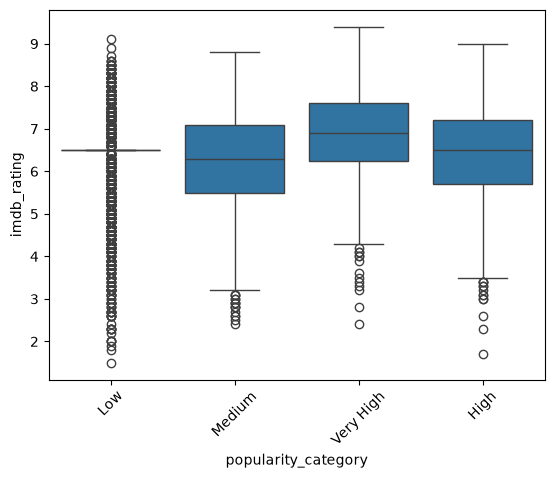

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(x='popularity_category',
            y='imdb_rating',
            data=df_movies)

plt.xticks(rotation=45)
plt.show()

In [7]:
import numpy as np

class Linear_regression:
    def fit(self,X,y):
        X, y = np.array(X), np.array(y)
        mx, my = X.mean(), y.mean()
        self.slop = ((X - mx)*(y - my)).sum()/((X - mx)**2).sum()
        self.intersept = my - self.slop*mx
        return self

    def predict(self,x):
        return self.slop*np.array(x)+self.intersept

model = Linear_regression().fit([2,3,4,5],[10,20,30,40])
print(model.predict([10]))


b = np.array([[1,2],
              [3,5]])
print(b.ndim, b.shape)

[90.]
2 (2, 2)


<class 'pandas.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Car ID        2500 non-null   int64  
 1   Brand         2500 non-null   str    
 2   Year          2500 non-null   int64  
 3   Engine Size   2500 non-null   float64
 4   Fuel Type     2500 non-null   str    
 5   Transmission  2500 non-null   str    
 6   Mileage       2500 non-null   int64  
 7   Condition     2500 non-null   str    
 8   Price         2500 non-null   float64
 9   Model         2500 non-null   str    
dtypes: float64(2), int64(3), str(5)
memory usage: 195.4 KB


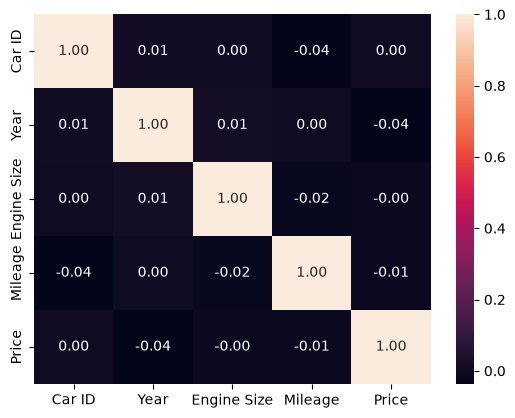

(2500, 10)

In [8]:
import pandas as pd
import seaborn as sn
import matplotlib.pyplot as plt

df=pd.read_csv(r'D:\python\pandas_practice\data\car_price_prediction_.csv')
df.info()
df.isnull().sum()

corr = df.corr(numeric_only=True)
sn.heatmap(corr,annot=True,fmt='.2f')
plt.show()
df.shape

In [9]:
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import GridSearchCV,train_test_split
from sklearn.metrics import make_scorer,r2_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

df=pd.read_csv(r'D:\python\pandas_practice\data\car_price_prediction_.csv')
X = df[['Brand','Year','Engine Size','Fuel Type','Transmission','Mileage','Condition']]
y = df['Price']

x_train,x_test,y_train,y_test = train_test_split(X,
                                                 y,
                                                 test_size=0.2,
                                                 random_state=42)

preprocess = ColumnTransformer(
    transformers=[('categorical',OneHotEncoder(handle_unknown='ignore'),['Brand','Fuel Type','Transmission',
                                                                         'Condition'])
            ],
            remainder='passthrough'
)

pipline = Pipeline([('preprocess',preprocess),('model',RandomForestRegressor())])
model = GridSearchCV(pipline,
                     param_grid={},
                     scoring={'r2':make_scorer(r2_score)},
                     refit='r2',
                     cv=10)

model.fit(x_train,y_train)
prediction = model.predict(x_test)

print(r2_score(y_test, prediction))

-0.05110960879263016


In [10]:
pd.DataFrame(model.cv_results_)


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,params,split0_test_r2,split1_test_r2,split2_test_r2,split3_test_r2,split4_test_r2,split5_test_r2,split6_test_r2,split7_test_r2,split8_test_r2,split9_test_r2,mean_test_r2,std_test_r2,rank_test_r2
0,0.572116,0.034313,0.016408,0.001846,{},-0.095718,-0.012355,0.009921,-0.083551,-0.06152,-0.081488,-0.048868,-0.035982,-0.13144,-0.088798,-0.06298,0.039998,1


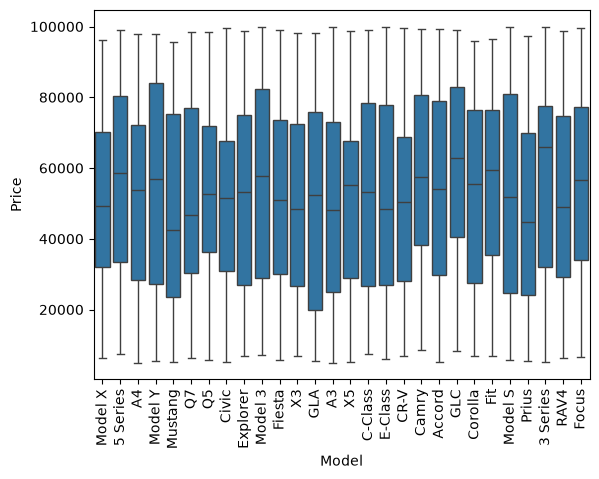

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.boxplot(x ='Model',y='Price',data=df)
plt.xticks(rotation=90)
plt.show()

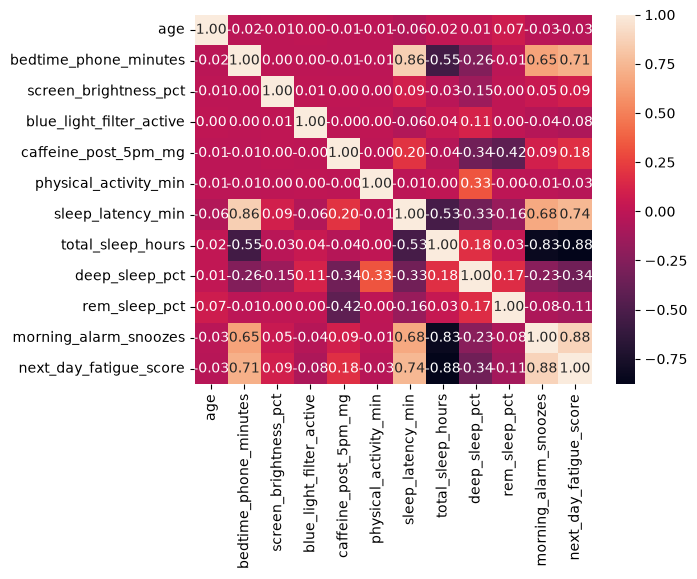

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
import pandas as pd
le = LabelEncoder()
df2 = pd.read_csv(r'D:\python\pandas_practice\data\bedtime_screentime_sleep_debt.csv')
df2.select_dtypes(include=['str','object'])

corr = df2.corr(numeric_only=True)
sns.heatmap(corr,annot = True,fmt='.2f')
plt.show()

In [100]:
import pandas as pd

df = pd.read_csv(r'D:\python\pandas_practice\data\bedtime_screentime_sleep_debt.csv')
# df.info()
# df.isnull().sum()
df.head(1)

,user_id,age,gender,occupation_type,chronotype,bedtime_phone_minutes,primary_bedtime_app,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,morning_alarm_snoozes,next_day_fatigue_score,sleep_debt_category
0,USR-00001,29,Female,Healthcare / Shift Worker,Intermediate,179,Instagram / Reddit,54,1,0,21,84.4,3.2,23.5,22.2,7,10.0,Severe Sleep Debt


In [101]:
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import classification_report, precision_score, accuracy_score,recall_score, f1_score,r2_score

df2 = pd.read_csv(r'D:\python\pandas_practice\data\bedtime_screentime_sleep_debt.csv')

X1 = df2[['age','gender','bedtime_phone_minutes','primary_bedtime_app','screen_brightness_pct',
         'caffeine_post_5pm_mg','physical_activity_min','sleep_latency_min','chronotype','occupation_type',
         'total_sleep_hours','deep_sleep_pct']]

y1 = df2['sleep_debt_category']

x_train,x_test,y_train,y_test = train_test_split(X1,
                                                 y1,
                                                 test_size=0.2,
                                                 random_state=42)

catogrical =['gender','primary_bedtime_app','chronotype','occupation_type']

numerical = ['screen_brightness_pct','caffeine_post_5pm_mg','physical_activity_min','sleep_latency_min',
             'total_sleep_hours','deep_sleep_pct']

preprocess = ColumnTransformer(
    transformers = [('catogrical',OneHotEncoder(handle_unknown='ignore'),catogrical),
                    ('StandardScaler',StandardScaler(),numerical)
                    ],
                    remainder="passthrough")

model = Pipeline([('preprocess',preprocess),('model',LogisticRegression(max_iter=50000))])
model1 = GridSearchCV(model,
                      param_grid={},
                      cv=5,
                      n_jobs=-1)

model1.fit(x_train,y_train)
predictt = model1.predict(x_test)

print(classification_report(y_test,predictt))
pd.DataFrame(model1.cv_results_)

                   precision    recall  f1-score   support

     Mild Deficit       0.97      0.99      0.98       374
    Moderate Debt       0.96      0.97      0.96       903
 Optimal Recovery       0.99      0.98      0.99       279
Severe Sleep Debt       0.82      0.78      0.80       144

         accuracy                           0.96      1700
        macro avg       0.94      0.93      0.93      1700
     weighted avg       0.96      0.96      0.96      1700



,mean_fit_time,std_fit_time,mean_score_time,std_score_time,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
0,2.038747,0.199064,0.007788,0.001436,{},0.964706,0.964706,0.968382,0.963235,0.957353,0.963676,0.00359,1


In [24]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split, GridSearchCV
df2 = pd.read_csv(r'D:\python\pandas_practice\data\bedtime_screentime_sleep_debt.csv')

X1 = df2[['age','gender','bedtime_phone_minutes','primary_bedtime_app','screen_brightness_pct',
         'caffeine_post_5pm_mg','physical_activity_min','sleep_latency_min','chronotype','occupation_type',
         'total_sleep_hours','deep_sleep_pct']]

y1 = df2['sleep_debt_category']

x_train,x_test,y_train,y_test = train_test_split(X1,
                                                 y1,
                                                 test_size=0.2,
                                                 random_state=42)

catogrical =['gender','primary_bedtime_app','chronotype','occupation_type']

numerical = ['screen_brightness_pct','caffeine_post_5pm_mg','physical_activity_min','sleep_latency_min',
             'total_sleep_hours','deep_sleep_pct']

preprocess = ColumnTransformer(
    transformers = [('catogrical',OneHotEncoder(handle_unknown='ignore'),catogrical),
                    ('StandardScaler',StandardScaler(),numerical)
                    ],
                    remainder="passthrough")

model = KNeighborsClassifier(weights='distance')
pipeline = Pipeline([('preprocess',preprocess),('model',model)])

model1 = GridSearchCV(pipeline,
                     param_grid={'model__n_neighbors':[int(v) for v in np.linspace(1,20,30)]},
                     cv=10,
                     n_jobs= -1)
model1.fit(x_train,y_train)
# predictt = model.predict(x_test)

pd.DataFrame(model1.cv_results_)

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_model__n_neighbors,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,split5_test_score,split6_test_score,split7_test_score,split8_test_score,split9_test_score,mean_test_score,std_test_score,rank_test_score
0,0.197300,0.002470,0.128733,0.001548,1,{'model__n_neighbors': 1},0.586765,0.604412,0.597059,0.623529,0.585294,0.639706,0.592647,0.617647,0.617647,0.635294,0.610000,0.018634,27
1,0.104367,0.046875,0.056183,0.037242,1,{'model__n_neighbors': 1},0.586765,0.604412,0.597059,0.623529,0.585294,0.639706,0.592647,0.617647,0.617647,0.635294,0.610000,0.018634,27
2,0.047141,0.025234,0.036294,0.001904,2,{'model__n_neighbors': 2},0.586765,0.604412,0.597059,0.623529,0.585294,0.639706,0.592647,0.617647,0.617647,0.635294,0.610000,0.018634,27
3,0.026777,0.002415,0.035279,0.003503,2,{'model__n_neighbors': 2},0.586765,0.604412,0.597059,0.623529,0.585294,0.639706,0.592647,0.617647,0.617647,0.635294,0.610000,0.018634,27
4,0.027944,0.002163,0.034786,0.001766,3,{'model__n_neighbors': 3},0.619118,0.632353,0.626471,0.647059,0.620588,0.635294,0.630882,0.652941,0.639706,0.655882,0.636029,0.012131,26
5,0.025700,0.001350,0.035692,0.002838,4,{'model__n_neighbors': 4},0.622059,0.644118,0.636765,0.675000,0.636765,0.658824,0.629412,0.645588,0.661765,0.647059,0.645735,0.015090,24
6,0.027477,0.003375,0.035970,0.002024,4,{'model__n_neighbors': 4},0.622059,0.644118,0.636765,0.675000,0.636765,0.658824,0.629412,0.645588,0.661765,0.647059,0.645735,0.015090,24
7,0.028512,0.004453,0.036553,0.003329,5,{'model__n_neighbors': 5},0.627941,0.651471,0.630882,0.679412,0.647059,0.666176,0.642647,0.663235,0.655882,0.657353,0.652206,0.015030,18
8,0.028164,0.003462,0.039829,0.008706,6,{'model__n_neighbors': 6},0.638235,0.650000,0.636765,0.686765,0.664706,0.667647,0.644118,0.650000,0.658824,0.651471,0.654853,0.014394,9
9,0.027564,0.003456,0.036222,0.001573,6,{'model__n_neighbors': 6},0.638235,0.650000,0.636765,0.686765,0.664706,0.667647,0.644118,0.650000,0.658824,0.651471,0.654853,0.014394,9


In [25]:
df2_2 = pd.DataFrame(model1.cv_results_)

C:\Users\Kaif Khan\AppData\Local\Temp\ipykernel_14124\1155624392.py:4: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


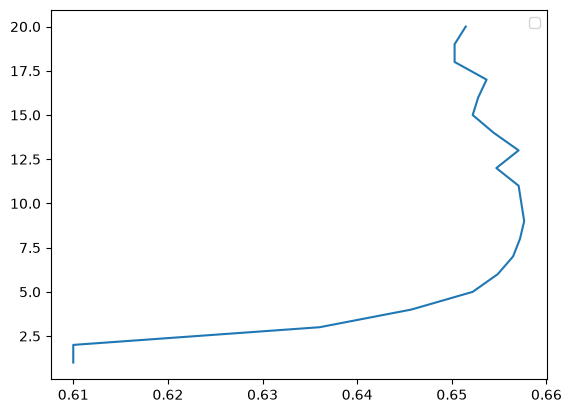

In [26]:
import matplotlib.pyplot as plt

plt.plot(df2_2['mean_test_score'],df2_2['param_model__n_neighbors'])
plt.legend()
plt.show()

In [27]:
import pandas as pd

df2 = pd.read_csv(r'D:\python\pandas_practice\data\ev_battery_failure_dataset.csv')
df2.describe()
df2['vehicle_brand'].isnull().sum()
df2['manufacturing_year'].isnull().median()
miss = df2.isnull().sum()
df2.shape

miss_percentage = (miss/len(df2))*100
miss_percentage


missing_info = pd.DataFrame({
    'missing_count': miss,
    'missing_percent': miss_percentage
})


missing_info.to_string()

number_data = df2.select_dtypes(include = 'number').columns
sting_data = df2.select_dtypes(include = 'string').columns

df2['manufacturing_year'].median()
df2['manufacturing_year']=df2['manufacturing_year'].fillna(float(df2['manufacturing_year'].median()))
df2['thermal_health_score'].isnull().sum()

df2[number_data] = df2[number_data].fillna(df2[number_data].median())

df2[sting_data] = df2[sting_data].fillna('Unknown')

df2.isnull().sum()

df2['manufacturing_year'].info()
df2_1 = df2.copy()

<class 'pandas.Series'>
RangeIndex: 200000 entries, 0 to 199999
Series name: manufacturing_year
Non-Null Count   Dtype  
--------------   -----  
200000 non-null  float64
dtypes: float64(1)
memory usage: 1.5 MB


In [32]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split, GridSearchCV

X1 = df2_1[['capacity_loss_percent','cell_voltage_std','cycle_count','odometer_km','voltage_imbalance',
      'thermal_runaway_risk','battery_stress_index','previous_faults','BMS_warning_count',
      'fast_charge_ratio','vehicle_age_years','average_charge_power_kw','aging_score','average_trip_distance',
      'daily_distance','internal_resistance','charging_cycles_last_month']]

y1 = df2_1['battery_failure']

x_train,x_test,y_train,y_test = train_test_split(X1,
                                                 y1,
                                                 test_size=0.2,
                                                 random_state=42)

model = KNeighborsClassifier(weights='distance')
pipeline = Pipeline([('preprocess',StandardScaler()),('model',model)])

model1 = GridSearchCV(pipeline,
                     param_grid={'model__n_neighbors':[1,3,5,7,9,11,14,17,21]},
                     cv=5,
                     n_jobs= -1)
model1.fit(x_train,y_train)
# predictt = model.predict(x_test)

pd.DataFrame(model1.cv_results_)

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_model__n_neighbors,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
0,0.262944,0.007863,25.097517,0.662078,1,{'model__n_neighbors': 1},0.940000,0.942813,0.939719,0.940813,0.941500,0.940969,0.001114,9
1,0.269330,0.010075,25.214291,0.620951,3,{'model__n_neighbors': 3},0.948594,0.950719,0.949937,0.952219,0.950438,0.950381,0.001174,8
2,0.174460,0.051293,24.933442,0.839365,5,{'model__n_neighbors': 5},0.952344,0.952937,0.952375,0.954375,0.952531,0.952912,0.000761,7
3,0.141580,0.023524,24.777775,1.061497,7,{'model__n_neighbors': 7},0.953750,0.954344,0.954000,0.955313,0.953594,0.954200,0.000611,6
4,0.115508,0.019174,25.543848,0.783375,9,{'model__n_neighbors': 9},0.954125,0.956125,0.954719,0.955562,0.954875,0.955081,0.000694,5
5,0.110513,0.008610,24.553306,0.358302,11,{'model__n_neighbors': 11},0.954625,0.957031,0.954625,0.956281,0.955656,0.955644,0.000939,4
6,0.107102,0.005384,25.024162,0.519850,14,{'model__n_neighbors': 14},0.954812,0.957156,0.955063,0.956750,0.956219,0.956000,0.000920,3
7,0.100285,0.002461,22.472900,1.663744,17,{'model__n_neighbors': 17},0.954937,0.957219,0.955375,0.957500,0.956906,0.956387,0.001032,1
8,0.100427,0.002048,20.644958,0.398911,21,{'model__n_neighbors': 21},0.954812,0.957125,0.955125,0.957438,0.957031,0.956306,0.001105,2


In [39]:
import pandas as pd

df1 = pd.read_csv(r'D:\python\pandas_practice\data\marketing_campaign.csv',sep='\t')

df1.describe()
df1.info()
df1.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   str    
 3   Marital_Status       2240 non-null   str    
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   str    
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   int64  
 16 

ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
AcceptedCmp3            0
AcceptedCmp4            0
AcceptedCmp5            0
AcceptedCmp1            0
AcceptedCmp2            0
Complain                0
Z_CostContact           0
Z_Revenue               0
Response                0
dtype: int64

In [40]:
df1['Income'] = df1['Income'].fillna(df1['Income'].median())
df1.isnull().sum()

ID                     0
Year_Birth             0
Education              0
Marital_Status         0
Income                 0
Kidhome                0
Teenhome               0
Dt_Customer            0
Recency                0
MntWines               0
MntFruits              0
MntMeatProducts        0
MntFishProducts        0
MntSweetProducts       0
MntGoldProds           0
NumDealsPurchases      0
NumWebPurchases        0
NumCatalogPurchases    0
NumStorePurchases      0
NumWebVisitsMonth      0
AcceptedCmp3           0
AcceptedCmp4           0
AcceptedCmp5           0
AcceptedCmp1           0
AcceptedCmp2           0
Complain               0
Z_CostContact          0
Z_Revenue              0
Response               0
dtype: int64

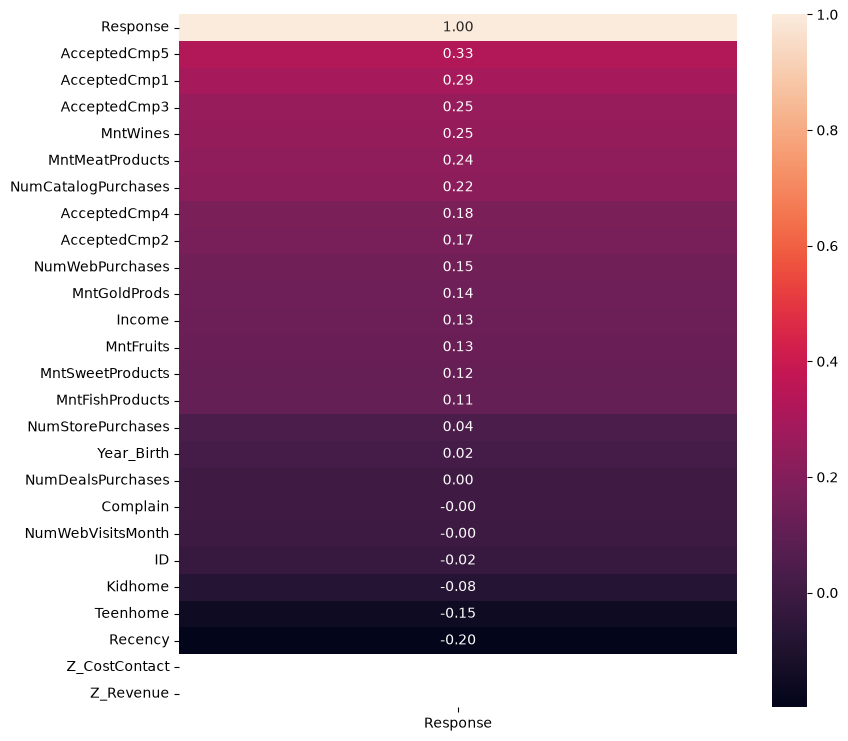

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(9,9))
# corr = df1.corr(numeric_only=True)
vall = corr['Response'].sort_values(ascending=False)
sns.heatmap(vall.to_frame(),annot=True,fmt='.2f')
plt.show()
# pd.DataFrame(vall)

In [91]:
print(df1['Marital_Status'].value_counts(),'\n')
print(df1['Education'].value_counts(),'\n')
print(df1['Year_Birth'].sort_values().head(),'\n')
print(df1['Income'].sort_values().tail())

df1['Marital_Status'] = df1['Marital_Status'].replace({'Divorced':'Single','Widow':'Single','Alone':'Single',
                                                       'Absurd':'Single','YOLO':'Single'})

df1['Education'] = df1['Education'].replace({'2n Cycle':'Graduation'})


Marital_Status
Married     864
Together    580
Single      480
Divorced    232
Widow        77
Alone         3
Absurd        2
YOLO          2
Name: count, dtype: int64 

Education
Graduation    1127
PhD            486
Master         370
2n Cycle       203
Basic           54
Name: count, dtype: int64 

239     1893
339     1899
192     1900
1950    1940
424     1941
Name: Year_Birth, dtype: int64 

164     157243.0
1300    157733.0
687     160803.0
617     162397.0
2233    666666.0
Name: Income, dtype: float64


In [92]:
df1['kids']=df1['Kidhome']+df1['Teenhome']
df1.columns
a = df1['AcceptedCmp1']
for i in range(2,6):
    a = df1[f'AcceptedCmp{i}'] + a

df1['totalAcceptedCmp'] = a

df1['totalMntproduct']=df1['MntMeatProducts']+df1['MntFishProducts']+df1['MntGoldProds']+df1['MntSweetProducts']

df1['totalNumdeal']=df1['NumDealsPurchases']+df1['NumCatalogPurchases']+df1['NumStorePurchases']

df1['Dt_Customer'] = pd.to_datetime(df1['Dt_Customer'], dayfirst=True)
df1['tenure_days'] = (df1['Dt_Customer'].max() - df1['Dt_Customer']).dt.days
df1

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,Complain,Z_CostContact,Z_Revenue,Response,kids,totalAcceptedCmp,totalMnt,totalNumdeal,tenure_days,totalMntproduct
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,0,3,11,1,0,0,1617,17,663,894
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,0,3,11,0,2,0,27,5,113,15
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,0,3,11,0,0,0,776,13,312,301
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,0,3,11,0,1,0,53,6,139,38
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,0,3,11,0,1,0,422,14,161,206
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2235,10870,1967,Graduation,Married,61223.0,0,1,2013-06-13,46,709,...,0,3,11,0,1,0,1341,9,381,589
2236,4001,1946,PhD,Together,64014.0,2,1,2014-06-10,56,406,...,0,3,11,0,3,1,444,14,19,38
2237,7270,1981,Graduation,Single,56981.0,0,0,2014-01-25,91,908,...,0,3,11,0,0,1,1241,17,155,285
2238,8235,1956,Master,Together,69245.0,0,1,2014-01-24,8,428,...,0,3,11,0,1,0,843,17,156,385


In [98]:
import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import classification_report, precision_score, accuracy_score,recall_score, f1_score,r2_score,make_scorer


catogrical =['Education','Marital_Status']

numerical = ['Year_Birth','Income','kids','Recency','totalNumdeal','Complain','totalAcceptedCmp','tenure_days',
             'NumWebVisitsMonth','totalMntproduct','MntWines','MntFruits',
             'MntMeatProducts','MntFishProducts','MntSweetProducts','MntGoldProds','NumDealsPurchases','NumWebPurchases','NumCatalogPurchases','NumStorePurchases',
             'AcceptedCmp3','AcceptedCmp4','AcceptedCmp5','AcceptedCmp1','AcceptedCmp2']

X1 = df1[catogrical+numerical]

y1 = df1['Response']

x_train,x_test,y_train,y_test = train_test_split(X1,
                                                 y1,
                                                 test_size=0.2,
                                                 random_state=42)


preprocess = ColumnTransformer(
    transformers = [('catogrical',OneHotEncoder(handle_unknown='ignore',sparse_output=False),catogrical),
                    ('StandardScaler',StandardScaler(),numerical)
                    ],
                    remainder="passthrough")

model = LogisticRegression(max_iter=100000)
# model2 = KNeighborsClassifier()
pipeline = Pipeline([('preprocess',preprocess),('model',model)])

model1 = GridSearchCV(pipeline,
                    #  param_grid={'model__n_neighbors':[int(v) for v in range(1,20)],
                    #              'model__weights':['uniform', 'distance'],
                    #              'model__metric':['manhattan','cosine','euclidean']},
                     param_grid={'model__class_weight':[{0:1,1:v} for v in range(1,10)],
                                 'model__C':[0.01,0.1,0.3,0.7,1,3,5]},
                     cv=5,
                     scoring={'precision':make_scorer(precision_score,zero_division=0),
                              'recall':make_scorer(recall_score,zero_division=0),
                              'f1':make_scorer(f1_score,zero_division=0)},
                     refit='f1',
                     n_jobs= -1)
model1.fit(x_train,y_train)
predictt = model1.predict(x_test)

a = pd.DataFrame(model1.cv_results_)
print(classification_report(y_test,predictt))


              precision    recall  f1-score   support

           0       0.92      0.89      0.90       379
           1       0.48      0.58      0.53        69

    accuracy                           0.84       448
   macro avg       0.70      0.73      0.71       448
weighted avg       0.85      0.84      0.85       448



In [99]:
a[['params', 'mean_test_f1', 'std_test_f1']].sort_values('mean_test_f1', ascending=False).head(10)

,params,mean_test_f1,std_test_f1
57,"{'model__C': 5, 'model__class_weight': {0: 1, ...",0.615460,0.050489
21,"{'model__C': 0.3, 'model__class_weight': {0: 1...",0.615420,0.038684
47,"{'model__C': 3, 'model__class_weight': {0: 1, ...",0.614805,0.056857
56,"{'model__C': 5, 'model__class_weight': {0: 1, ...",0.614805,0.056857
48,"{'model__C': 3, 'model__class_weight': {0: 1, ...",0.613329,0.049811
20,"{'model__C': 0.3, 'model__class_weight': {0: 1...",0.613291,0.055753
38,"{'model__C': 1, 'model__class_weight': {0: 1, ...",0.612360,0.055852
11,"{'model__C': 0.1, 'model__class_weight': {0: 1...",0.611061,0.060033
30,"{'model__C': 0.7, 'model__class_weight': {0: 1...",0.610998,0.047147
39,"{'model__C': 1, 'model__class_weight': {0: 1, ...",0.610998,0.047147


In [95]:
import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.compose import ColumnTransformer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import classification_report, precision_score, accuracy_score,recall_score, f1_score,r2_score,make_scorer

catogrical =['Education','Marital_Status']

numerical = ['Year_Birth','Income','kids','Recency','totalNumdeal','Complain','totalAcceptedCmp','tenure_days',
             'NumWebVisitsMonth','NumWebPurchases','totalMntproduct','MntWines','MntFruits']

X1 = df1[catogrical+numerical]

y1 = df1['Response']

x_train,x_test,y_train,y_test = train_test_split(X1,
                                                 y1,
                                                 test_size=0.2,
                                                 random_state=42)


preprocess = ColumnTransformer(
    transformers = [('catogrical',OneHotEncoder(handle_unknown='ignore',sparse_output=False),catogrical),
                    ('StandardScaler',StandardScaler(),numerical)
                    ],
                    remainder="passthrough") 

# model = LogisticRegression(max_iter=100000,class_weight='balanced')
model2 = KNeighborsClassifier()
pipeline = Pipeline([('preprocess',preprocess),('SMOTE',SMOTE(random_state=42)),('model',model2)])

model1 = GridSearchCV(pipeline,
                     param_grid={'model__n_neighbors':[int(v) for v in range(1,70)],
                                 'model__weights':['uniform', 'distance'],
                                 'model__metric':['manhattan','cosine','euclidean']},
                    #  param_grid={'model__class_weight':[{0:1,1:v} for v in range(1,10)]},
                     cv=5,
                     scoring={'precision':make_scorer(precision_score,zero_division=0),
                              'recall':make_scorer(recall_score,zero_division=0),
                              'f1':make_scorer(f1_score,zero_division=0)},
                     refit='f1',
                     n_jobs= -1)
model1.fit(x_train,y_train)
predictt = model1.predict(x_test)

a = pd.DataFrame(model1.cv_results_)
print(classification_report(y_test,predictt))

              precision    recall  f1-score   support

           0       0.94      0.81      0.87       379
           1       0.40      0.71      0.51        69

    accuracy                           0.79       448
   macro avg       0.67      0.76      0.69       448
weighted avg       0.86      0.79      0.81       448



In [96]:
a[['params', 'mean_test_f1', 'std_test_f1']].sort_values('mean_test_f1', ascending=False).head(10)

,params,mean_test_f1,std_test_f1
124,"{'model__metric': 'manhattan', 'model__n_neigh...",0.567036,0.042713
132,"{'model__metric': 'manhattan', 'model__n_neigh...",0.566813,0.042996
137,"{'model__metric': 'manhattan', 'model__n_neigh...",0.565933,0.044227
125,"{'model__metric': 'manhattan', 'model__n_neigh...",0.563969,0.037295
130,"{'model__metric': 'manhattan', 'model__n_neigh...",0.563527,0.039887
134,"{'model__metric': 'manhattan', 'model__n_neigh...",0.563371,0.048487
127,"{'model__metric': 'manhattan', 'model__n_neigh...",0.562615,0.043506
136,"{'model__metric': 'manhattan', 'model__n_neigh...",0.562385,0.051104
135,"{'model__metric': 'manhattan', 'model__n_neigh...",0.562101,0.044513
131,"{'model__metric': 'manhattan', 'model__n_neigh...",0.562082,0.044665


In [1]:
import pandas as pd
df6 = pd.read_csv(r'D:\python\pandas_practice\data\test.csv')

# df2.describe()

# df6['Departure Delay in Minutes'] = df6['Departure Delay in Minutes'].fillna(df6['Departure Delay in Minutes'].median())
df6['Arrival Delay in Minutes'] = df6['Arrival Delay in Minutes'].fillna(df6['Arrival Delay in Minutes'].median())
# df6.columns
# df6.info()
df6['satisfaction'] = df6['satisfaction'].map({'satisfied':1,'neutral or dissatisfied':0})
df6.isnull().sum()

Unnamed: 0                           0
id                                   0
Gender                               0
Customer Type                        0
Age                                  0
Type of Travel                       0
Class                                0
Flight Distance                      0
Inflight wifi service                0
Departure/Arrival time convenient    0
Ease of Online booking               0
Gate location                        0
Food and drink                       0
Online boarding                      0
Seat comfort                         0
Inflight entertainment               0
On-board service                     0
Leg room service                     0
Baggage handling                     0
Checkin service                      0
Inflight service                     0
Cleanliness                          0
Departure Delay in Minutes           0
Arrival Delay in Minutes             0
satisfaction                         0
dtype: int64

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.model_selection import train_test_split,GridSearchCV
from sklearn.metrics import classification_report,f1_score,precision_score,recall_score,make_scorer

# df6 = pd.read_csv(r'D:\python\pandas_practice\data\test.csv')
# df6['Departure Delay in Minutes'] = df2['Departure Delay in Minutes'].fillna(df2['Departure Delay in Minutes'].median())

numerical = ['Age','Flight Distance','Inflight wifi service','Departure/Arrival time convenient',
        'Ease of Online booking','Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
        'Inflight entertainment','On-board service', 'Leg room service','Baggage handling', 'Checkin service', 
        'Inflight service','Cleanliness','Departure Delay in Minutes', 'Arrival Delay in Minutes']

catogrical = ['Type of Travel','Class','Gender']

x = df6[numerical+catogrical]
y = df6['satisfaction']

x1_train,x1_test,y1_train,y1_test = train_test_split(x,y,test_size=0.2,random_state=42)

preprocesss = ColumnTransformer(transformers=
                               [('catogrical',OneHotEncoder(handle_unknown='ignore',sparse_output=False),catogrical),
                                ('numerical',StandardScaler(),numerical)],
                                remainder="passthrough")

pipline = Pipeline([('preprocess',preprocesss),('model',KNeighborsClassifier())])

model7 = GridSearchCV(pipline,
                     param_grid={'model__n_neighbors':[v for v in range(1,40)],
                                 'model__weights':['uniform', 'distance'],
                                 'model__metric':['manhattan','cosine','euclidean']},
                     cv=5,
                     scoring= {'precision':make_scorer(precision_score),
                               'recall':make_scorer(recall_score),
                               'f1':make_scorer(f1_score)},
                     refit='f1',
                     n_jobs=-1)

model7.fit(x1_train,y1_train)
pridect1 = model7.predict(x1_test)

# print(classification_report(y1_test,pridect1))
v = pd.DataFrame(model7.cv_results_)

In [4]:
print(classification_report(y1_test,pridect1))

              precision    recall  f1-score   support

           0       0.86      0.97      0.91      2945
           1       0.95      0.79      0.86      2251

    accuracy                           0.89      5196
   macro avg       0.90      0.88      0.88      5196
weighted avg       0.90      0.89      0.89      5196



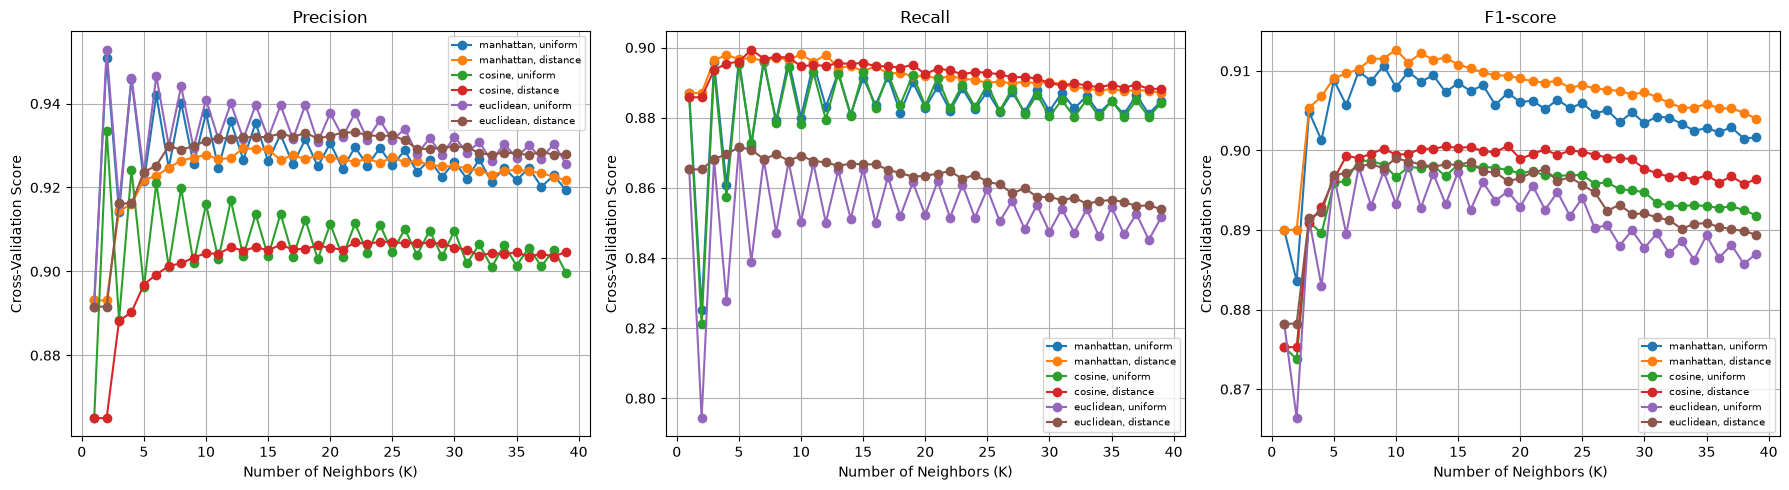

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

v = pd.DataFrame(model7.cv_results_)

scores = [
    ('mean_test_precision', 'Precision'),
    ('mean_test_recall', 'Recall'),
    ('mean_test_f1', 'F1-score')
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (score, title) in zip(axes, scores):

    for metric in v['param_model__metric'].unique():
        for weight in v['param_model__weights'].unique():

            subset = v[
                (v['param_model__metric'] == metric) &
                (v['param_model__weights'] == weight)
            ].sort_values('param_model__n_neighbors')

            ax.plot(
                subset['param_model__n_neighbors'].astype(int),
                subset[score],
                marker='o',
                label=f'{metric}, {weight}'
            )

    ax.set_xlabel('Number of Neighbors (K)')
    ax.set_ylabel('Cross-Validation Score')
    ax.set_title(title)
    ax.grid(True)
    ax.legend(fontsize=7)

plt.tight_layout()
plt.show()

In [196]:
v

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_model__metric,param_model__n_neighbors,param_model__weights,params,split0_test_precision,split1_test_precision,...,std_test_recall,rank_test_recall,split0_test_f1,split1_test_f1,split2_test_f1,split3_test_f1,split4_test_f1,mean_test_f1,std_test_f1,rank_test_f1
0,0.028939,0.000815,1.568313,0.045981,manhattan,1,uniform,"{'model__metric': 'manhattan', 'model__n_neigh...",0.894065,0.896061,...,0.006339,23,0.887177,0.895327,0.886880,0.893803,0.886933,0.890024,0.003740,40
1,0.035712,0.001083,1.576799,0.044682,manhattan,1,distance,"{'model__metric': 'manhattan', 'model__n_neigh...",0.894065,0.896061,...,0.006339,23,0.887177,0.895327,0.886880,0.893803,0.886933,0.890024,0.003740,40
2,0.037037,0.004145,1.587072,0.073016,manhattan,2,uniform,"{'model__metric': 'manhattan', 'model__n_neigh...",0.951111,0.948557,...,0.005649,52,0.879624,0.882920,0.884088,0.889083,0.882232,0.883589,0.003113,45
3,0.040329,0.002275,1.615867,0.045717,manhattan,2,distance,"{'model__metric': 'manhattan', 'model__n_neigh...",0.894065,0.896061,...,0.006339,23,0.887177,0.895327,0.886880,0.893803,0.886933,0.890024,0.003740,40
4,0.035238,0.003290,1.568495,0.044484,manhattan,3,uniform,"{'model__metric': 'manhattan', 'model__n_neigh...",0.914027,0.914365,...,0.008972,17,0.898027,0.909091,0.904305,0.912300,0.900471,0.904839,0.005282,13
5,0.046022,0.008231,1.527914,0.038004,manhattan,3,distance,"{'model__metric': 'manhattan', 'model__n_neigh...",0.915110,0.914964,...,0.009243,12,0.898833,0.909940,0.904905,0.911846,0.901221,0.905349,0.004959,12
6,0.037859,0.004212,1.564499,0.040772,manhattan,4,uniform,"{'model__metric': 'manhattan', 'model__n_neigh...",0.946177,0.946770,...,0.009121,47,0.892672,0.903797,0.904422,0.905682,0.899857,0.901286,0.004727,14
7,0.036165,0.003477,1.567063,0.069155,manhattan,4,distance,"{'model__metric': 'manhattan', 'model__n_neigh...",0.917940,0.919489,...,0.007616,2,0.901612,0.911894,0.905454,0.910091,0.904907,0.906792,0.003717,10
8,0.040016,0.004453,1.571843,0.045950,manhattan,5,uniform,"{'model__metric': 'manhattan', 'model__n_neigh...",0.921848,0.921361,...,0.007336,11,0.901786,0.911700,0.907131,0.913212,0.910299,0.908825,0.004052,8
9,0.034134,0.002697,1.582661,0.030171,manhattan,5,distance,"{'model__metric': 'manhattan', 'model__n_neigh...",0.923341,0.921919,...,0.008029,8,0.901928,0.912252,0.907433,0.912804,0.911056,0.909094,0.004042,7


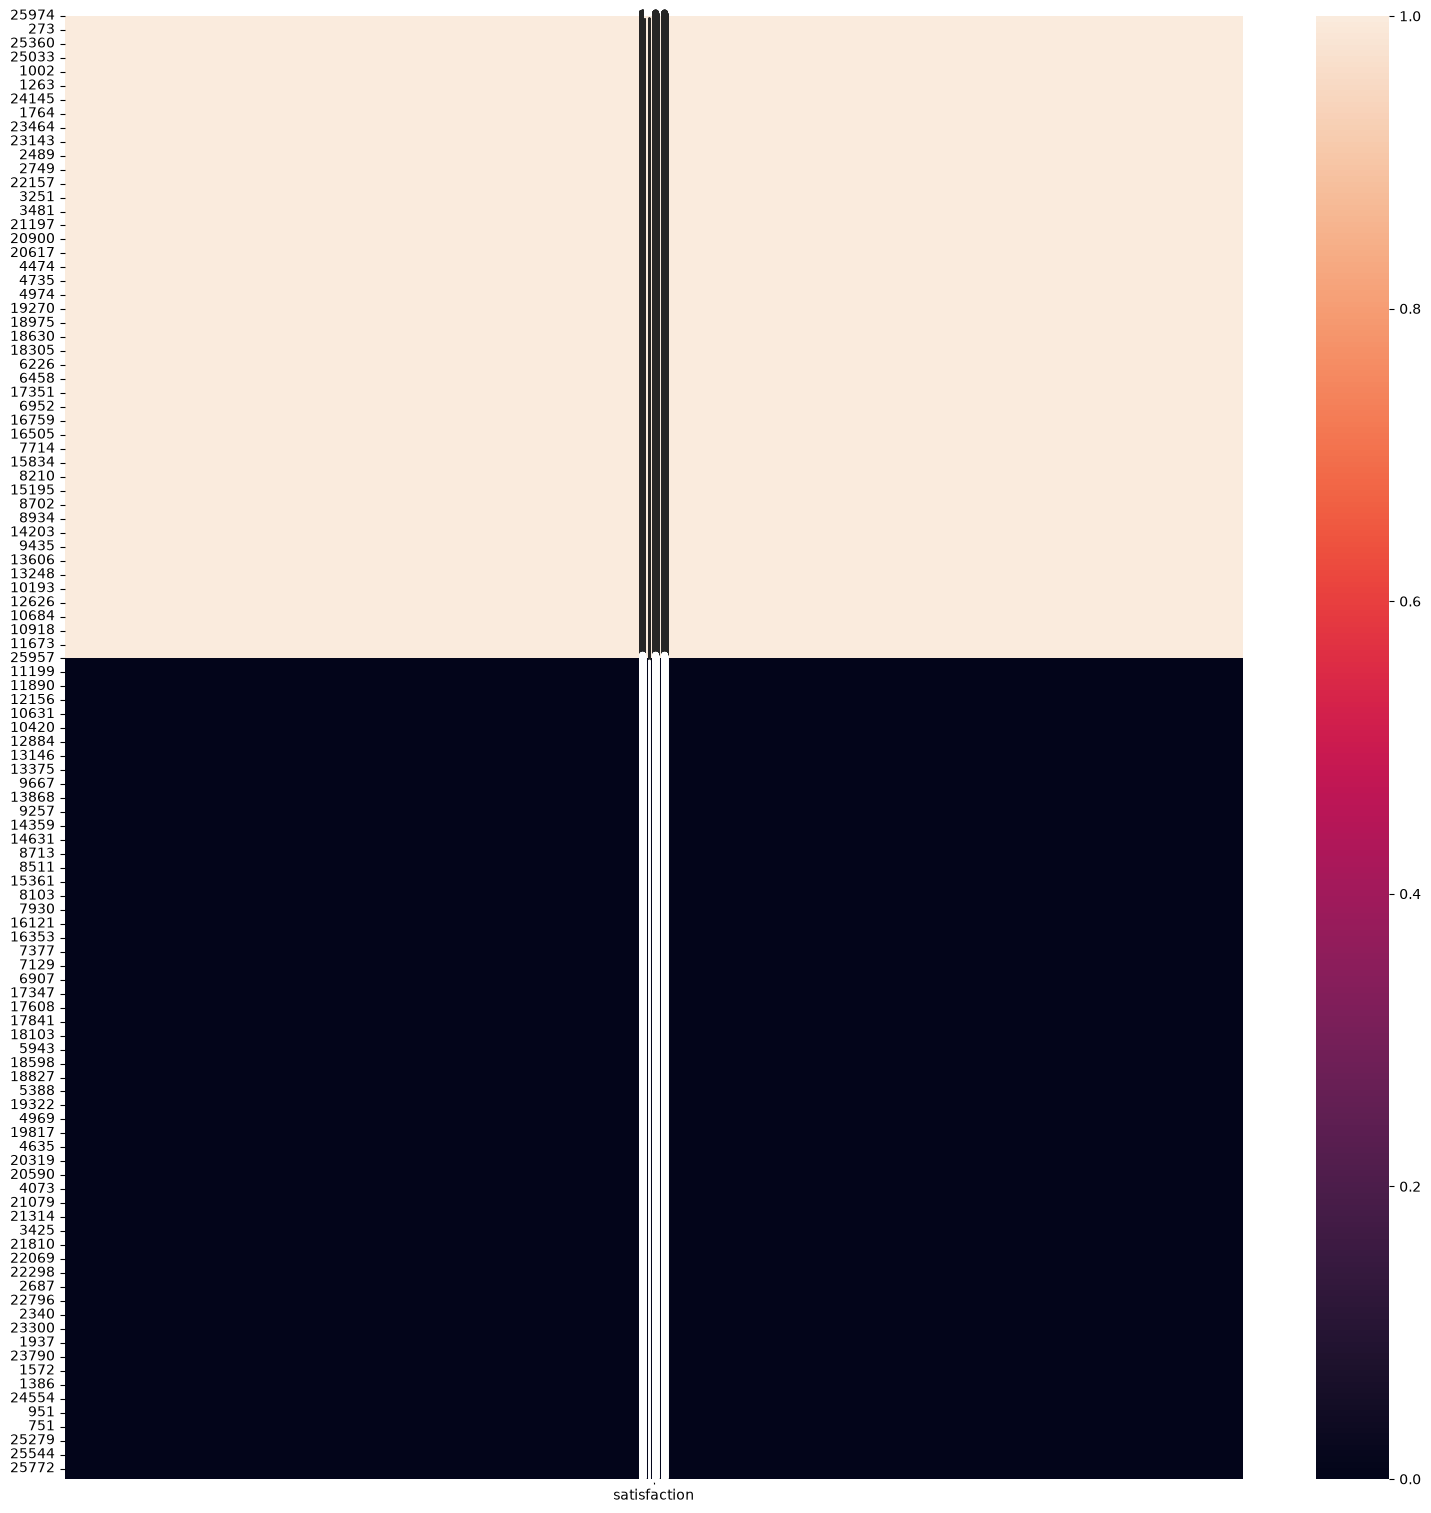

In [164]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(19,19))
corr = df6.corr(numeric_only=True)
a = df6['satisfaction'].map({'satisfied':1,'neutral or dissatisfied':0})
vall = a.sort_values(ascending=False)
sns.heatmap(vall.to_frame(),annot=True,fmt='.2f')
plt.show()